# NN_L7_context_lengths

**Lecture 7 of Neural Networks and Deep Learning (NN), attention and transformers. Length in WordPiece tokens (FinBERT tokenizer) of finance tweets, Financial PhraseBank sentences and ECB speeches, against the 512-token window of BERT.**

Neural Networks and Deep Learning (NN), Lecture 7 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L7/NN_L7_context_lengths/NN_L7_context_lengths.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Token counts computed with the FinBERT tokenizer (ProsusAI/finbert) in lectures/L7/analysis_L7.py.

median tokens, tweets = 25   [len.tw_median]
median tokens, ECB speeches = 3338   [len.sp_median]
speeches above 512 tokens (%) = 98.8   [len.sp_pct_over512]


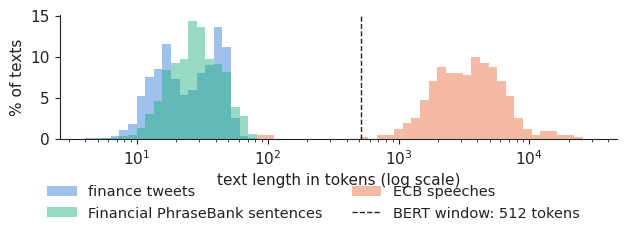

In [3]:
t = pd.read_csv(REPO + 'lectures/L7/results/' + 'token_lengths.csv')
sp, tw, pb = (t.tokens[t.corpus == c].values for c in ['speeches', 'tweets', 'phrasebank'])
show('len.tw_median', 'median tokens, tweets', int(np.median(tw)))
show('len.sp_median', 'median tokens, ECB speeches', int(np.median(sp)))
show('len.sp_pct_over512', 'speeches above 512 tokens (%)', round(100 * float(np.mean(sp > 512)), 1))
bins = np.logspace(np.log10(4), np.log10(30000), 60)
fig, ax = plt.subplots(figsize=(6.4, 2.4))
for v, c, lab in [(tw, PAL['data'], 'finance tweets'), (pb, PAL['benchmark'], 'Financial PhraseBank sentences'), (sp, PAL['model'], 'ECB speeches')]:
    ax.hist(v, bins=bins, weights=np.full(len(v), 100.0 / len(v)), histtype='stepfilled', alpha=0.45, color=c, label=lab)
ax.axvline(512, color='#222222', lw=1, ls='--', label='BERT window: 512 tokens')
ax.set_xscale('log')
ax.set_xlabel('text length in tokens (log scale)'); ax.set_ylabel('% of texts')
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('context_lengths.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()